# 비지도 학습 — 군집화와 K-Means

수업 필기 `비지도학습_K_Means` 와 메모(`1일_비지도학습_K_Means.txt` 의 군집화 부분)를 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `머신러닝` v6 p.128~133 — 16. 비지도 학습)

- 원본에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다.
- 그림 · **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 미리 만들어 두었습니다.

> 실습 데이터 `iris_dataset.csv` (붓꽃 150송이) 는 이 노트북과 **같은 폴더**에 있어야 합니다.

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. 비지도 학습과 군집화 (교재 p.129)

| | 분류 (지도 학습) | 군집화 (비지도 학습) |
|---|---|---|
| 정답(레이블) | **있음** — 학습에 사용 | **없음** (기준이 없다) |
| 하는 일 | 정해진 범주(Yes / No, 품종) 를 **예측** | 비슷한 데이터끼리 **스스로 그룹(클러스터)** 을 만든다 |
| 예 | 이 고객은 이탈할까? | 고객을 구매 패턴이 비슷한 몇 개 집단으로 나누면? |

**좋은 군집의 기준**
1. **군집 간 분산 최대화** — 서로 다른 집단은 최대한 **멀리** (이질성 최대)
2. **군집 내 분산 최소화** — 같은 집단 안은 최대한 **촘촘하게** (유사성 최대)

## 2. 데이터 — 붓꽃의 꽃잎 길이 · 너비

In [2]:
import numpy as np
import pandas as pd

# 데이터 불러오기 (노트북과 같은 폴더)
df = pd.read_csv('./iris_dataset.csv')
print(df.shape)
df.head()

(150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),label
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


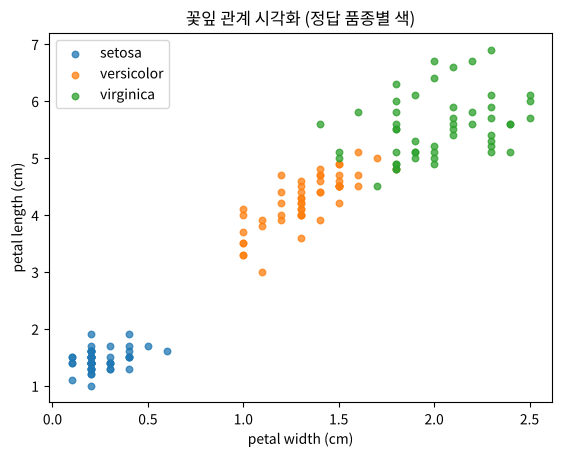

In [3]:
# 꽃잎 길이와 너비의 관계 — 정답(품종) 색은 '확인용'으로만 칠한다
fig, ax = plt.subplots(figsize=(6.5, 4.8))
for name, color in zip(['setosa', 'versicolor', 'virginica'], ['tab:blue', 'tab:orange', 'tab:green']):
    part = df[df['label'] == name]
    ax.scatter(part['petal width (cm)'], part['petal length (cm)'], s=22, alpha=0.75, color=color, label=name)
ax.set_xlabel('petal width (cm)'); ax.set_ylabel('petal length (cm)')
ax.set_title('꽃잎 관계 시각화 (정답 품종별 색)')
ax.legend()
plt.show()

> 필기는 `plotly.express.scatter` 로 그렸는데, plotly 그림은 GitHub 미리보기에서 보이지 않아 matplotlib 로 바꿨다.
> plotly 로 보고 싶다면 : `px.scatter(df, x='petal width (cm)', y='petal length (cm)', color='label', title='꽃잎 관계 시각화')`

In [4]:
# 군집화에 사용할 데이터 : 꽃잎 길이, 꽃잎 너비 (정답 label 은 넣지 않는다!)
wl_data = df[['petal length (cm)', 'petal width (cm)']]
wl_data.describe().round(2)

,petal length (cm),petal width (cm)
count,150.00,150.00
mean,3.76,1.20
std,1.77,0.76
min,1.00,0.10
25%,1.60,0.30
50%,4.35,1.30
75%,5.10,1.80
max,6.90,2.50


## 3. K-Means 원리 (교재 p.130)

1. **K 개의 중심점**을 임의로 찍는다
2. 각 데이터를 **유클리드 거리**가 가장 가까운 중심점에 할당 → 클러스터 생성
3. 각 클러스터에 속한 데이터들의 **좌표 평균**으로 중심점을 옮긴다
4. 옮긴 중심점 기준으로 2 → 3 을 반복
5. 중심점이 더 이상 움직이지 않으면(할당이 바뀌지 않으면) **종료**

In [5]:
# 위 5단계를 numpy 로 직접 구현
def kmeans_manual(X, k, seed=0, max_iter=100):
    rng = np.random.default_rng(seed)
    centers = X[rng.choice(len(X), size=k, replace=False)]           # 1. 데이터 중 k 개를 첫 중심점으로
    for it in range(1, max_iter + 1):
        dist = np.sqrt(((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2))   # (n, k) 유클리드 거리
        labels = dist.argmin(axis=1)                                   # 2. 가장 가까운 중심점에 할당
        new_centers = np.array([X[labels == j].mean(axis=0) for j in range(k)])   # 3. 좌표 평균으로 이동
        if np.allclose(new_centers, centers):                          # 5. 움직이지 않으면 종료
            break
        centers = new_centers                                          # 4. 반복
    sse = ((X - centers[labels]) ** 2).sum()                           # 군집 내 오차제곱합
    return labels, centers, sse, it

X = wl_data.to_numpy()
labels_m, centers_m, sse_m, n_iter = kmeans_manual(X, k=3, seed=0)
print("반복 횟수 :", n_iter)
print("중심점 :\n", centers_m.round(2))
print("클러스터별 개수 :", np.bincount(labels_m))
print("SSE :", round(sse_m, 2))

반복 횟수 : 8
중심점 :
 [[1.46 0.25]
 [4.29 1.36]
 [5.63 2.05]]
클러스터별 개수 : [50 54 46]
SSE : 31.41


![K-Means 반복 애니메이션](./images/anim_04_kmeans_steps.gif)

🎬 위 함수를 한 단계씩 그렸다. **✕ 가 중심점**, 배경색은 "이 위치에 점이 있으면 어느 중심점이 가장 가까운가"(할당 영역). ① 할당 → ② 중심점 이동을 반복하다가 **중심점이 멈추면 끝**. 중심점이 옮겨간 자리는 언제나 그 색 점들의 **한가운데(좌표 평균)** 다.

> **📝 고친 부분** (메모)
> - "X축과 Y축과 **엔트로픽**이 가까운 것끼리 묶는다" → 엔트로피(결정 트리)가 아니라 **유클리드 거리**가 가까운 것끼리.
> - "각 데이터 가까운 데이터 간 **거리의 평균**을 계산 → 중심점 다시 지정" → 새 중심점은 거리의 평균이 아니라 클러스터에 속한 데이터들의 **좌표(x, y) 평균**이다(그래서 이름이 K-**Means**). 교재 p.130 의 "데이터 간 거리의 평균을 계산" 도 같은 뜻으로 읽어야 한다.

## 4. scikit-learn `KMeans` (교재 p.131)

```python
from sklearn.cluster import KMeans
model = KMeans(n_clusters=k, random_state=0)   # k : 클러스터 개수 (사람이 정한다)
model.fit_predict(data)                        # 학습 + 각 데이터의 클러스터 번호
```

In [6]:
from sklearn.cluster import KMeans

# 필기 그대로 : 클러스터 2개
model1 = KMeans(n_clusters=2, random_state=0)
output1 = model1.fit_predict(wl_data)
print(output1)
print("클러스터별 개수 :", np.bincount(output1))

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]
클러스터별 개수 : [99 51]


In [7]:
# 정답과 비교 (군집화에는 정답을 쓰지 않았고, 확인할 때만 본다)
pd.crosstab(df['label'], output1, rownames=['정답 품종'], colnames=['클러스터'])

클러스터,0,1
정답 품종,,
setosa,0,50
versicolor,49,1
virginica,50,0


k=2 로 나누면 **setosa(50) vs 나머지(100)** 로 나뉜다. 꽃잎이 작은 setosa 가 다른 두 품종과 확실히 떨어져 있기 때문.
단, versicolor 1송이(98번, 꽃잎 길이 3.0 · 너비 1.1)는 가장 작은 versicolor 라 setosa 쪽 중심에 더 가까워서 같이 묶였다.

> 클러스터 **번호(0, 1)에는 의미가 없다** — "1 = setosa" 가 아니라 그냥 "1번 그룹". 실행 환경이 바뀌면 번호가 뒤바뀔 수도 있다.

In [8]:
# 클러스터 3개 — 실제 품종 수와 같게
model3 = KMeans(n_clusters=3, random_state=0)
output3 = model3.fit_predict(wl_data)

print("클러스터별 개수 :", np.bincount(output3))
print("중심점 (길이, 너비) :\n", model3.cluster_centers_.round(2))
print("SSE (inertia_) :", round(model3.inertia_, 2), " / 직접 구현 :", round(sse_m, 2))
pd.crosstab(df['label'], output3, rownames=['정답 품종'], colnames=['클러스터'])

클러스터별 개수 : [52 50 48]
중심점 (길이, 너비) :
 [[4.27 1.34]
 [1.46 0.25]
 [5.6  2.04]]
SSE (inertia_) : 31.37  / 직접 구현 : 31.41


클러스터,0,1,2
정답 품종,,,
setosa,0,50,0
versicolor,48,0,2
virginica,4,0,46


{0: 'versicolor', 1: 'setosa', 2: 'virginica'}
정답과 일치 : 96.0%  (150송이 중 144송이)


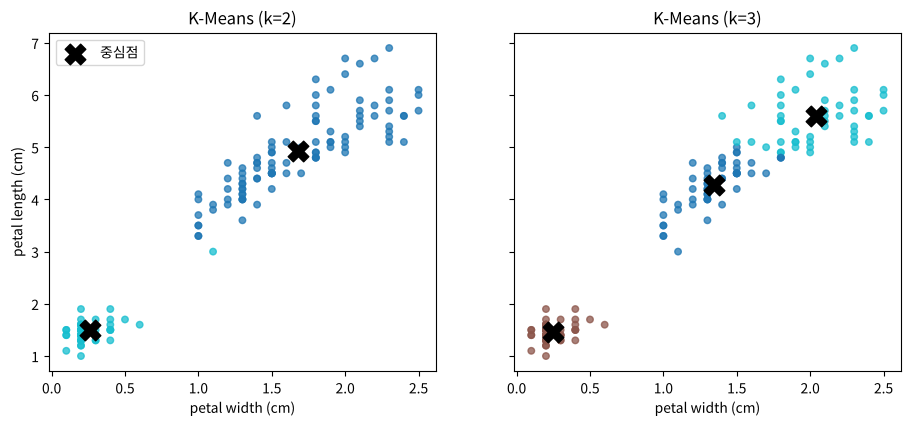

In [9]:
# 각 클러스터에서 가장 많은 품종을 그 클러스터의 이름으로 → 정답과 얼마나 일치?
mapping = pd.crosstab(output3, df['label']).idxmax(axis=1)
print(mapping.to_dict())
match = (pd.Series(output3).map(mapping) == df['label']).mean()
print(f"정답과 일치 : {match:.1%}  (150송이 중 {int(match * 150)}송이)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, k, out, m in [(axes[0], 2, output1, model1), (axes[1], 3, output3, model3)]:
    ax.scatter(wl_data['petal width (cm)'], wl_data['petal length (cm)'], c=out, cmap='tab10', s=22, alpha=0.75)
    ax.scatter(m.cluster_centers_[:, 1], m.cluster_centers_[:, 0], marker='X', s=220, c='black', label='중심점')
    ax.set_title(f'K-Means (k={k})'); ax.set_xlabel('petal width (cm)')
axes[0].set_ylabel('petal length (cm)'); axes[0].legend()
plt.show()

> 직접 구현은 SSE 31.41, sklearn 은 31.37 — 첫 중심점에 따라 조금 다른 곳에서 멈출 수 있다. sklearn 은 첫 중심점을 바꿔 가며 여러 번(`n_init`) 실행하고 SSE 가 가장 작은 결과를 고른다.

정답을 한 번도 보지 않았는데 **96%(144송이)** 가 실제 품종과 같은 그룹으로 묶였다. 틀린 6송이는 versicolor 와 virginica 가 겹치는 경계에 있다.

## 5. K 는 몇 개가 좋을까 — 엘보우(Elbow) 방법 (교재 p.132)

- `inertia_` = **SSE** (각 점과 자기 중심점 사이 거리 제곱의 합) = 군집 내 분산
- K 를 늘리면 SSE 는 **항상 줄어든다**(K = 150 이면 0) → "가장 작은 SSE" 가 아니라 **크게 줄다가 완만해지는 꺾인 지점(팔꿈치)** 을 고른다.

k= 1 : SSE =  550.90
k= 2 : SSE =   86.39
k= 3 : SSE =   31.37
k= 4 : SSE =   19.48
k= 5 : SSE =   14.13
k= 6 : SSE =   11.83
k= 7 : SSE =    9.83
k= 8 : SSE =    8.04
k= 9 : SSE =    6.76
k=10 : SSE =    6.38


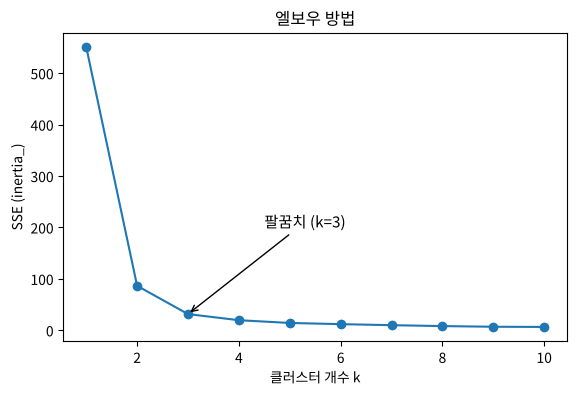

In [10]:
sse_list = []
k_range = range(1, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=0).fit(wl_data)
    sse_list.append(km.inertia_)

for k, sse in zip(k_range, sse_list):
    print(f"k={k:>2} : SSE = {sse:7.2f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(list(k_range), sse_list, marker='o')
ax.annotate('팔꿈치 (k=3)', xy=(3, sse_list[2]), xytext=(4.5, 200),
            arrowprops=dict(arrowstyle='->'), fontsize=11)
ax.set_xlabel('클러스터 개수 k'); ax.set_ylabel('SSE (inertia_)')
ax.set_title('엘보우 방법')
plt.show()

![엘보우 애니메이션](./images/anim_05_elbow.gif)

🎬 k 를 1 → 8 로 늘리면서 왼쪽은 군집 결과, 오른쪽은 SSE 곡선. 550.9 → 86.4 → **31.4** 까지는 크게 줄지만 그 뒤로는 19.5 · 14.1 … 조금씩만 준다 → **k = 3** 이 팔꿈치. (실제 품종 수도 3)

### 주의 — K-Means 는 거리 기반

- 특성의 **단위 · 범위가 다르면 스케일링**(`StandardScaler`) 후 군집화한다 (오늘은 둘 다 cm 라 그대로 사용).
- 특성을 많이 넣는다고 좋아지지 않는다 — 붓꽃 4개 특성을 모두 쓰면 일치율이 **89%** 로 오히려 떨어진다(꽃받침은 품종 구분에 도움이 덜 됨). 고차원이면 **PCA 로 줄인 뒤 군집화**하기도 한다.
- 결과가 **첫 중심점에 따라 달라질 수 있다** → sklearn 은 `k-means++`(서로 멀리 떨어진 첫 중심점)로 여러 번(`n_init`) 실행해 SSE 가 가장 작은 결과를 고른다.

In [11]:
# 4개 특성을 모두 쓰면?
X4 = df.drop(columns=['label'])
out4 = KMeans(n_clusters=3, random_state=0).fit_predict(X4)
map4 = pd.crosstab(out4, df['label']).idxmax(axis=1)
print(f"4개 특성 K-Means 정답 일치 : {(pd.Series(out4).map(map4) == df['label']).mean():.1%}")

4개 특성 K-Means 정답 일치 : 88.7%


> **📝 고친 부분** (`비지도학습_K_Means`)
> - 쓰지 않는 `#from sklearn.cluster import k_means`(함수형) 와 `#w_data = ...` 주석 정리, 실제로 쓴 `KMeans`(클래스) 만 남김
> - 데이터 경로 `C:\\Users\\...\\iris_dataset.csv` → `./iris_dataset.csv`
> - `fit_predict` 결과를 숫자 나열(`print(output1)`)로만 보고 끝 → 정답과의 교차표 · 산점도 · k=3 · 엘보우까지 이어서 확인

### 다음 시간 (교재 p.134~)
GMM(가우시안 혼합 모델) — K-Means 는 동그란 군집을 가정하지만, GMM 은 **타원형 정규 분포**들이 섞여 있다고 보고 각 점이 각 군집에 속할 **확률**을 준다.